# KJK StatScript — Series 1: Foundations of Quantitative Reasoning
## Module 1: What Is Probability?
## Episode 1.4: Python Implementation — Proving Probability Axioms with Real Data 

### About the Course
KJK StatScript is an educational platform designed to bridge theoretical probability, computational data science, and East African macroeconomic policy.

### Module Focus: 
Moving from abstract textbook abstractions (dice, cards, urns) to empirical, measure-theoretic probability grounded in real-world data.

### Approach: 
"Just-In-Time" Syntax Callouts. Programming concepts are introduced at the exact moment they are required to solve a statistical problem, ensuring complete beginners can follow along without losing sight of the underlying mathematics.

### Core Objective of Episode 1.4: 
To translate Kolmogorov’s Axioms of Probability, established theoretically in **Episode 1.2** into executable Python code using a 45.8-year East African climate time series.

## About the DatasetOverview
This notebook analyzes the Kampala Subnational Dekadal Rainfall Dataset (1981–2026), derived from the United Nations World Food Programme (WFP) Vulnerability Analysis and Mapping (VAM) data engine and the Climate Hazards Group InfraRed Precipitation with Stations (CHIRPS).

## Technical & Geographic Specifications
- Geographic Unit: Kampala District, Uganda
- Administrative Hierarchy: Administrative Level 2 (adm_level = 2)
- UN OCHA Place Code (PCODE): UG1002 (adm_id = 999571)
- Spatial Grid Resolution: n_pixels = 19 ($\approx 475\text{ km}^2$ spatial aggregation across $5\text{ km} \times 5\text{ km}$ satellite cells)
- Temporal Resolution: Dekads (10-Day Intervals)
    - Dekad 1: Days 1–10 of the month (YYYY-MM-01)
    - Dekad 2: Days 11–20 of the month (YYYY-MM-11)
    - Dekad 3: Day 21 to the end of the month (YYYY-MM-21)
- Sample Space Dimension ($N$): 1,650 dekads (36 dekads/year across 45.8 years from January 1981 to October 2026)

## Data Dictionary

| Variable Name | Data Type | Units / Format | Description |
|---|---|---|---|
| `date` | object / datetime | MM/DD/YYYY | Start date of the 10-day dekad |
| `adm_level` | int64 | Category (2) | Administrative boundary tier (Level 2 = District) |
| `adm_id` | int64 | Numeric ID | Unique WFP database identifier (999571) |
| `PCODE` | object | String Code | UN OCHA standardized spatial code (UG1002) |
| `n_pixels` | int64 | Integer Count | Number of satellite grid cells covering the district (19) |
| `rfh` | float64 | Millimeters ($mm$) | Rainfall Height: Observed dekadal precipitation |
| `rfh_avg` | float64 | Millimeters ($mm$) | Historical Baseline: 30-year dekadal mean |
| `rfq` | float64 | Percentage ($\%$) | Rainfall Anomaly Ratio: $\left(\frac{\text{rfh}}{\text{rfh\_avg}}\right) \times 100\%$ |

# Environment Setup & Data Loading
## Python Micro-Hint 1: Packages & DataFrames
- import pandas as pd: Imports pandas, Python’s digital spreadsheet library. The as pd convention creates a **shorter nickname**.

- import matplotlib.pyplot as plt: Imports Python’s core **data visualization engine**.

- pd.read_csv(): Loads tabular data from a CSV file into a memory-structure called a DataFrame (in this case named **df**).

# Data Analysis

## Importing Relevant Libraries

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

## Load Kampala Dekadal Dataset (1981 - 2026) 

In [17]:
df = pd.read_csv("Kampala_Dekad_Data_since_1981_to_2026.csv")

### Viewing how the data looks like and about the dataset

In [20]:
df.head()

,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q
0,1/1/1981,2,999571,UG1002,19,18.789474,17.214035,NaN,NaN,NaN,NaN,107.092094,NaN,NaN
1,1/11/1981,2,999571,UG1002,19,6.157895,17.903510,NaN,NaN,NaN,NaN,48.716960,NaN,NaN
2,1/21/1981,2,999571,UG1002,19,9.210526,16.778948,34.157894,51.896492,NaN,NaN,65.248910,68.823040,NaN
3,2/1/1981,2,999571,UG1002,19,6.052631,16.175438,21.421053,50.857895,NaN,NaN,52.195526,47.300484,NaN
4,2/11/1981,2,999571,UG1002,19,31.105263,18.500000,46.368420,51.454388,NaN,NaN,153.639400,90.991010,NaN


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1650 entries, 0 to 1649
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       1650 non-null   object 
 1   adm_level  1650 non-null   int64  
 2   adm_id     1650 non-null   int64  
 3   PCODE      1650 non-null   object 
 4   n_pixels   1650 non-null   int64  
 5   rfh        1650 non-null   float64
 6   rfh_avg    1650 non-null   float64
 7   r1h        1648 non-null   float64
 8   r1h_avg    1648 non-null   float64
 9   r3h        1642 non-null   float64
 10  r3h_avg    1642 non-null   float64
 11  rfq        1650 non-null   float64
 12  r1q        1648 non-null   float64
 13  r3q        1642 non-null   float64
dtypes: float64(9), int64(3), object(2)
memory usage: 180.6+ KB


## Measure Total Sample Space Size (N)

In [27]:
N = len(df)
N

1650

## Variable Selection and continuing with rainfall height in millimeters(mm)
## Python Micro-Hint 2: Variable Extraction & Boolean Comparison Masks
- rfh_mm = df["rfh"]: Assigns the target precipitation column to a dedicated variable for clean, readable vector expressions.
- Comparison Operators (>=, <, &): Evaluate every element in rfh_mm row-by-row and return a vector of True (1) and False (0) values. The bitwise & operator combines multiple logical conditions.

In [30]:
rfh_mm = df["rfh"]

In [32]:
rfh_mm.head()

0    18.789474
1     6.157895
2     9.210526
3     6.052631
4    31.105263
Name: rfh, dtype: float64

In [36]:
rfh_mm.tail()

1645    39.526318
1646    37.210526
1647    32.789474
1648    33.105263
1649    37.368420
Name: rfh, dtype: float64

# Defining Mathematical Events (Set-Theoretic Logic) 
From Episode 1.2, we define our sample space $\Omega$ as all observed Kampala dekads ($N = 1,650$). We set up the following disjoint and non-disjoint events based on precipitation thresholds ($\text{rfh}$):
- Event $A$ (Wet Dekad): $\text{rfh} \ge 20.0\text{ mm}$
- Event $A^c$ (Dry / Low-Rain Dekad): $\text{rfh} < 20.0\text{ mm}$
- Event $B$ (Heavy Rain Dekad): $\text{rfh} \ge 50.0\text{ mm}$
- Event $C$ (Moderate Rain Dekad): $20.0\text{ mm} \le \text{rfh} < 50.0\text{ mm}$

In [47]:
# 1. Event A: Wet Dekad (rfh_mm >= 20.0mm)
df["is_wet"] = rfh_mm >= 20.0

# 2. Event A^c: Dry Dekad (rfh_mm < 20.0mm)
df["is_dry"] = rfh_mm < 20.0

# 3. Event B: Heavy Rain Dekad (rfh_mm >= 50.0mm)
df["is_heavy"] = rfh_mm >= 50.0

# 4. Event C: Moderate Rain Dekad (20.0mm <= rfh_mm < 50.0mm)
df["is_moderate"] = (rfh_mm >= 20.0) & (rfh_mm < 50.0)

# Display sample of boolean mask table
print("Sample Event Masks")
print(
    df[["rfh", "is_wet", "is_dry", "is_heavy", "is_moderate"]]
    .head(10)
    .to_string()
)

Sample Event Masks
         rfh  is_wet  is_dry  is_heavy  is_moderate
0  18.789474   False    True     False        False
1   6.157895   False    True     False        False
2   9.210526   False    True     False        False
3   6.052631   False    True     False        False
4  31.105263    True   False     False         True
5   4.000000   False    True     False        False
6  10.052631   False    True     False        False
7  75.842100    True   False      True        False
8  69.157900    True   False      True        False
9  49.105263    True   False     False         True


### Python Micro-Hint 3: The .mean() Boolean Averaging TrickIn Python
- True equals 1 and False equals 0. Calling .mean() on a boolean Series sums all True values ($n_E$) and divides by the total number of rows ($N$):$$P(E) = \frac{\text{sum}(\text{True})}{N} = \frac{n_E}{N}$$

In [52]:
# Compute empirical probabilities by averaging boolean masks
p_A = df["is_wet"].mean()
p_Ac = df["is_dry"].mean()
p_B = df["is_heavy"].mean()
p_C = df["is_moderate"].mean()

# Extract event counts
n_A = df["is_wet"].sum()
n_Ac = df["is_dry"].sum()
n_B = df["is_heavy"].sum()
n_C = df["is_moderate"].sum()

print("Empirical Dekadal Probabilities (N = 1,650)")
print(
    f"P(A)   [Wet Dekad (>=20mm)]:       {p_A:.4f}  ({p_A * 100:.2f}%) | Count: {n_A}"
)
print(
    f"P(A^c) [Dry Dekad (<20mm)]:        {p_Ac:.4f}  ({p_Ac * 100:.2f}%) | Count: {n_Ac}"
)
print(
    f"P(B)   [Heavy Rain (>=50mm)]:      {p_B:.4f}  ({p_B * 100:.2f}%) | Count: {n_B}"
)
print(
    f"P(C)   [Moderate Rain (20-50mm)]:  {p_C:.4f}  ({p_C * 100:.2f}%) | Count: {n_C}"
)

Empirical Dekadal Probabilities (N = 1,650)
P(A)   [Wet Dekad (>=20mm)]:       0.6309  (63.09%) | Count: 1041
P(A^c) [Dry Dekad (<20mm)]:        0.3691  (36.91%) | Count: 609
P(B)   [Heavy Rain (>=50mm)]:      0.1752  (17.52%) | Count: 289
P(C)   [Moderate Rain (20-50mm)]:  0.4558  (45.58%) | Count: 752


# Programmatic Verification of Kolmogorov's Axioms
We now test whether our empirical estimates satisfy Kolmogorov’s foundational probability rules derived in Episode 1.2:
- Axiom 1 & 2 (Non-negativity & Normalization): $0 \le P(E) \le 1$ and $P(\Omega) = 1.0$.
- Proof 1 — The Complement Rule: $P(A) + P(A^c) = 1.0$.
- Proof 2 — Additivity for Disjoint Sets: Since $B \cap C = \emptyset$ and $A = B \cup C$:$$P(A) = P(B \cup C) = P(B) + P(C)$$
- Proof 3 — Monotonicity: Since $B \subseteq A$ (Heavy rain is a subset of Wet dekads):$$P(B) \le P(A)$$

## Python Micro-Hint 4: == vs = and assert
- **=**: Assigns a value to a variable.
- **==**: Tests if two expressions are equal, returning True or False.
- **assert**: Evaluates a condition; if True, execution continues silently. If False, it stops execution and raises an error.

In [60]:
print("Kolmogorov Axiom Verifications\n")

# Verification 1: Complement Rule P(A) + P(A^c) == 1.0
complement_sum = p_A + p_Ac
print(f"1. Complement Rule Check:")
print(f"   P(A) + P(A^c) = {p_A:.4f} + {p_Ac:.4f} = {complement_sum:.4f}")
assert abs(complement_sum - 1.0) < 1e-6, "Complement rule failed!"
print("   RESULT: Verified Mathematically (P(A^c) = 1 - P(A))\n")

# Verification 2: Additivity for Disjoint Sets P(B U C) == P(B) + P(C) == P(A)
disjoint_sum = p_B + p_C
print(f"2. Disjoint Additivity Check (A = B U C):")
print(
    f"   P(B) + P(C) = {p_B:.4f} + {p_C:.4f} = {disjoint_sum:.4f} | P(A) = {p_A:.4f}"
)
assert abs(disjoint_sum - p_A) < 1e-6, "Additivity axiom failed!"
print("   RESULT: Verified Mathematically (P(B U C) = P(B) + P(C))\n")

# Verification 3: Monotonicity Property (B subset of A => P(B) <= P(A))
print(f"3. Monotonicity Check (B subset of A):")
print(
    f"   P(B) [{p_B:.4f}] <= P(A) [{p_A:.4f}] is {p_B <= p_A} ({p_B:.4f} <= {p_A:.4f})"
)
assert p_B <= p_A, "Monotonicity condition failed!"
print("   RESULT: Verified Mathematically (P(B) <= P(A))\n")

print("STATUS: All Kolmogorov Probability Axioms Verified in Python!")

Kolmogorov Axiom Verifications

1. Complement Rule Check:
   P(A) + P(A^c) = 0.6309 + 0.3691 = 1.0000
   RESULT: Verified Mathematically (P(A^c) = 1 - P(A))

2. Disjoint Additivity Check (A = B U C):
   P(B) + P(C) = 0.1752 + 0.4558 = 0.6309 | P(A) = 0.6309
   RESULT: Verified Mathematically (P(B U C) = P(B) + P(C))

3. Monotonicity Check (B subset of A):
   P(B) [0.1752] <= P(A) [0.6309] is True (0.1752 <= 0.6309)
   RESULT: Verified Mathematically (P(B) <= P(A))

STATUS: All Kolmogorov Probability Axioms Verified in Python!


# Visualizing the Sample Space Partition ($\Omega$)
- To conclude the analysis, we plot a visual partition of our sample space $\Omega = 1,650\text{ dekads}$.
- The three disjoint event sets $A^c$ (Dry), $C$ (Moderate), and $B$ (Heavy) completely cover $\Omega$ without overlapping:$$\Omega = A^c \cup C \cup B \quad \implies \quad P(\Omega) = P(A^c) + P(C) + P(B) = 1.0$$

## Python Micro-Hint 5: Basic Matplotlib Bar Charts
- plt.bar(x, y): Constructs vertical bar charts.
- plt.savefig(): Exports graphics to high-resolution files (e.g., 300 DPI) for academic reports.

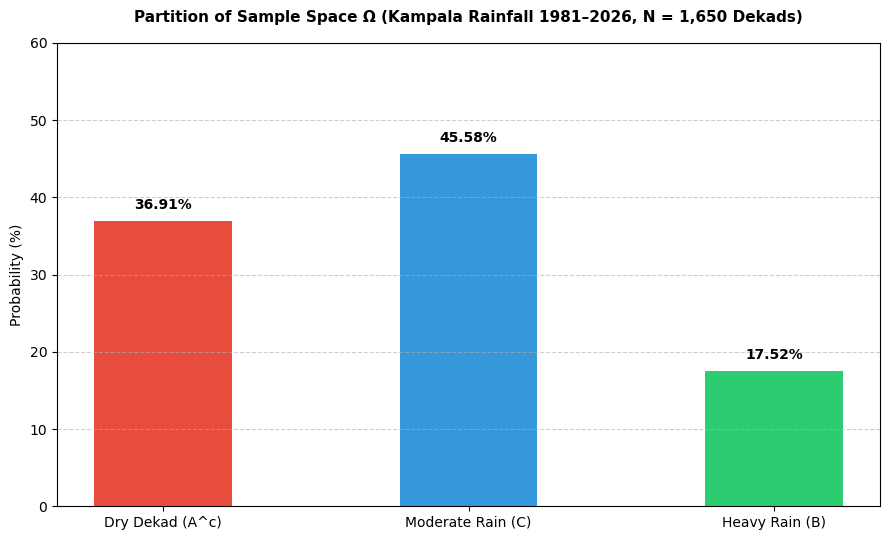

In [64]:
# Define disjoint partition categories
categories = ["Dry Dekad (A^c)", "Moderate Rain (C)", "Heavy Rain (B)"]
probabilities = [p_Ac * 100, p_C * 100, p_B * 100]
colors = ["#e74c3c", "#3498db", "#2ecc71"]

plt.figure(figsize=(9, 5.5))
bars = plt.bar(categories, probabilities, color=colors, width=0.45)

# Annotate exact percentages on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 1.2,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.title(
    "Partition of Sample Space Ω (Kampala Rainfall 1981–2026, N = 1,650 Dekads)",
    fontsize=11,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Probability (%)", fontsize=10)
plt.ylim(0, 60)
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Export graphic for Episode 1.7 Academic Report Writing
plt.tight_layout()
plt.savefig("python_sample_space_partition.png", dpi=300)
plt.show()

# Empirical Insights
An analysis of the Kampala Subnational Dekadal Rainfall Dataset (1981–2026) across $N = 1,650$ dekads yields the following key statistical properties:
- High Baseline Probability of Rainfall ($P(A) = 63.09\%$): Over the 45.8-year period, nearly two-thirds of all 10-day dekads in Kampala recorded at least $20.0\text{ mm}$ of rainfall ($n_A = 1,041\text{ dekads}$).
- Moderate Rain Dominates the Sample Space ($P(C) = 45.58\%$): Moderate dekadal rainfall ($20.0\text{ mm} \le \text{rfh} < 50.0\text{ mm}$) accounts for the largest partition of the sample space ($n_C = 752\text{ dekads}$), representing standard operational moisture levels.
- Low Frequency of Heavy Rain / Flood Risk ($P(B) = 17.52\%$): Dekads with extreme precipitation ($\text{rfh} \ge 50.0\text{ mm}$) occur in less than 1 in 5 dekads ($n_B = 289\text{ dekads}$), confirming that extreme events occupy a strict subset of total wet dekads.
- Dry Dekad Occurrence ($P(A^c) = 36.91\%$): Dry dekads ($\text{rfh} < 20.0\text{ mm}$) occur in approximately 37% of all observed periods ($n_{A^c} = 609\text{ dekads}$), reflecting Kampala's distinct bimodal dry season windows (January–February and June–July).

# Mathematical & Methodological Summary

This computational notebook successfully bridges measure-theoretic probability theory with practical Python data engineering:

**Axiomatic Soundness:** Kolmogorov's three probability axioms hold programmatically across the entire 45.8-year climate record:

- **Normalization:** $P(\Omega) = P(A^c \cup C \cup B) = 36.91\% + 45.58\% + 17.52\% = 100.0\%$.
- **Complement Rule:** $P(A) + P(A^c) = 0.6309 + 0.3691 = 1.0000$.
- **Additivity for Disjoint Sets:** $P(B \cup C) = P(B) + P(C) = 0.1752 + 0.4558 = 0.6309 = P(A)$.
- **Monotonicity:** $P(B) \le P(A) \implies 0.1752 \le 0.6309$.

**Efficiency of Boolean Vectorization:** Using pandas Series comparison masks (`rfh_mm >= 20.0`) combined with the `.mean()` method provides a vectorized $O(N)$ execution pattern that eliminates slow Python `for` loops when computing empirical probabilities.

**Reproducible Proofing:** Leveraging Python's `assert` statement enforces mathematical verification in automated analytical pipelines, preventing bad data or silent errors from passing downstream into policy models.

# Institutional & Practical Recommendations

## For Statistical Researchers & Students

- **Adopt Explicit Variable Extraction:** Always isolate target metric columns into dedicated `Series` variables (e.g., `rfh_mm = df["rfh"]`) before applying logical boolean masks to maintain clean, readable code architecture.
- **Export Visual Assets for Institutional Reports:** Save high-resolution chart exports (`plt.savefig("python_sample_space_partition.png", dpi=300)`) directly into structured `assets` folders for cross-referencing in Microsoft Word and LaTeX document compilation (Episode 1.7).

## For Institutional Policy Analysts (UBOS, NPA, Bank of Uganda)

- **Integrate Dekadal Baselines into Climate Risk Planning:** Utilize the baseline probability $P(\text{rfh} \ge 20\text{mm}) = 63.09\%$ and heavy rainfall risk $P(\text{rfh} \ge 50\text{mm}) = 17.52\%$ to anchor agricultural monitoring, urban drainage planning under Uganda's NDP IV, and disaster resilience frameworks.
- **Maintain Automated Audit Trails:** Embed programmatic `assert` checks within automated data pipeline scripts to verify statistical properties automatically whenever fresh dekadal data feeds are appended from CHIRPS or WFP sources.